# 01 · Comprendre les données Lending Club et la cible ALM

Ce notebook est le premier d'une série de trois qui racontent le projet de **monitoring MLOps d'un
modèle ALM de remboursement anticipé** construit sur les données Lending Club (Kaggle). Il ne contient
aucune logique métier : toute la préparation est faite par le package `alm_monitoring`, le notebook se
contente de l'appeler et de commenter les résultats.

**Plan**

1. Le problème métier : pourquoi une banque modélise le remboursement anticipé
2. Du fichier Kaggle brut au jeu préparé (`load_lending_club`, `prepare_lending_club`)
3. Volumes et taux de prepayment par cohorte annuelle
4. Le biais de censure et le choix d'une cible à horizon fixe (12 mois)
5. Ce qui bouge dans le temps : taux d'intérêt, FICO, DTI
6. Valeurs manquantes
7. Conclusion

## 1. Le problème métier

Un prêt à la consommation à taux fixe peut être soldé **avant son terme contractuel** : c'est le
*remboursement anticipé* (prepayment). Pour la gestion actif-passif (ALM), ce comportement est
déterminant :

* il modifie l'**écoulement** des actifs (les flux de capital arrivent plus tôt que prévu) ;
* il crée un **risque de taux** : quand les taux baissent, les clients refinancent, la banque
  réinvestit à un taux plus bas ; quand les taux montent, ils gardent leur prêt bon marché ;
* il alimente les mesures réglementaires de risque de taux du portefeuille bancaire (IRRBB).

Un **modèle comportemental** estime donc, pour chaque prêt à l'octroi, la probabilité qu'il soit
remboursé par anticipation. Contrairement à un score de crédit, ce qui compte en ALM n'est pas tant
le classement des prêts que le **niveau** prédit : si le modèle annonce 13 % de remboursements
anticipés alors qu'il y en a 17 %, l'écoulement projeté du bilan est faux. C'est ce qui justifiera,
dans les notebooks suivants, l'accent mis sur la calibration.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = "notebook+png"  # +png : figure statique visible sur GitHub
pd.set_option("display.max_rows", 30)
pd.set_option("display.width", 140)

from alm_monitoring.data import lending_club as lc

ROOT = ".."
print("Cible :", lc.TARGET, "| date :", lc.TIMESTAMP, "| horizon :", lc.HORIZON_MONTHS, "mois")

Cible : prepaid_12m | date : issue_d | horizon : 12 mois


## 2. Du fichier Kaggle brut au jeu préparé

Le fichier Kaggle `accepted_2007_to_2018Q4.csv` décrit 2,26 millions de prêts. Pour illustrer la
chaîne de préparation sans charger 1,6 Go, on utilise un **échantillon stratifié de 62 277 prêts** au
format brut. `load_lending_club` lit uniquement les colonnes utiles avec des types compacts
(`float32`, `category`).

In [2]:
raw = lc.load_lending_club(f"{ROOT}/data/sample/lending_club_sample.csv.gz")
print(raw.shape)
raw.head(5)

(62277, 28)


,id,loan_amnt,term,int_rate,installment,grade,emp_length,home_ownership,annual_inc,verification_status,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,last_pymnt_d,application_type,mort_acc,pub_rec_bankruptcies
0,1017981,4800.0,36 months,8.90,152.419998,A,6 years,OWN,42000.0,Not Verified,...,5.0,0.0,177.0,3.100000,13.0,f,Dec-2014,Individual,NaN,0.0
1,110749970,10000.0,36 months,7.21,309.739990,A,NaN,OWN,42000.0,Not Verified,...,17.0,0.0,5606.0,5.900000,31.0,w,Mar-2019,Individual,2.0,0.0
2,135151982,13500.0,36 months,7.46,419.690002,A,1 year,MORTGAGE,90000.0,Source Verified,...,11.0,0.0,13290.0,52.299999,36.0,w,Mar-2019,Individual,7.0,0.0
3,129615093,12000.0,60 months,15.04,285.739990,C,3 years,MORTGAGE,30000.0,Verified,...,20.0,1.0,20810.0,45.700001,24.0,w,Mar-2019,Joint App,2.0,1.0
4,667298,12000.0,36 months,6.92,370.089996,A,10+ years,MORTGAGE,145000.0,Source Verified,...,13.0,0.0,14538.0,14.000000,34.0,f,Mar-2014,Individual,NaN,0.0


`prepare_lending_club` applique trois règles :

1. **features connues à l'émission uniquement** ;
2. **cible à horizon fixe** `prepaid_12m` : prêt soldé (*Fully Paid*) dans les 12 mois suivant
   l'émission et au moins un mois avant le terme contractuel ;
3. **cohortes observables uniquement** : une cohorte n'est gardée que si ses 12 mois sont écoulés
   à la date d'arrêté du fichier (mars 2019).

In [3]:
prepared = lc.prepare_lending_club(raw)
print(
    f"{len(raw):,} prêts bruts -> {len(prepared):,} prêts préparés "
    f"(cohortes dont l'horizon de {lc.HORIZON_MONTHS} mois est écoulé)"
)
print("Taux de prepayment sur l'échantillon :", round(prepared[lc.TARGET].mean(), 3))
prepared.head(5)

62,277 prêts bruts -> 57,559 prêts préparés (cohortes dont l'horizon de 12 mois est écoulé)
Taux de prepayment sur l'échantillon : 0.127


,id,issue_d,prepaid_12m,loan_amnt,term_months,int_rate,installment,annual_inc,dti,fico,...,mort_acc,pub_rec,pub_rec_bankruptcies,inq_last_6mths,grade,home_ownership,purpose,verification_status,application_type,earliest_cr_line
0,1017981,2011-11-01,0,4800.0,36.0,8.90,152.419998,42000.0,6.740000,737.0,...,NaN,0.0,0.0,1.0,A,OWN,debt_consolidation,Not Verified,Individual,Dec-2001
1,110749970,2017-06-01,0,10000.0,36.0,7.21,309.739990,42000.0,5.490000,707.0,...,2.0,0.0,0.0,0.0,A,OWN,home_improvement,Not Verified,Individual,Nov-1992
2,129615093,2018-03-01,0,12000.0,60.0,15.04,285.739990,30000.0,49.689999,672.0,...,2.0,1.0,1.0,2.0,C,MORTGAGE,debt_consolidation,Verified,Joint App,Nov-2007
3,667298,2011-02-01,0,12000.0,36.0,6.92,370.089996,145000.0,3.530000,782.0,...,NaN,0.0,0.0,1.0,A,MORTGAGE,debt_consolidation,Source Verified,Individual,Mar-1991
4,552310,2010-07-01,1,13750.0,36.0,13.98,469.809998,46996.0,18.590000,702.0,...,NaN,0.0,0.0,0.0,C,MORTGAGE,debt_consolidation,Not Verified,Individual,Oct-2004


### Les colonnes post-octroi bannies

Le fichier Kaggle contient le **résultat** de chaque prêt : paiements reçus, date du dernier
paiement, capital restant dû, recouvrements… Les utiliser comme variables explicatives serait une
fuite de données (le modèle « verrait » la réponse). Ces colonnes sont listées une fois pour toutes
dans `lc.POST_ORIGINATION_COLUMNS` et vérifiées par l'audit de fuite du notebook 02.

In [4]:
print(f"{len(lc.POST_ORIGINATION_COLUMNS)} colonnes post-octroi interdites :")
print(", ".join(lc.POST_ORIGINATION_COLUMNS))
print()
print("Colonnes brutes chargées :", sorted(raw.columns))
print()
print("Colonnes du jeu préparé   :", sorted(prepared.columns))
assert not set(prepared.columns) & set(lc.POST_ORIGINATION_COLUMNS), "fuite !"
print()
print(
    f"{len(lc.NUMERIC_FEATURES)} features numériques + {len(lc.CATEGORICAL_FEATURES)} catégorielles :",
    ", ".join(lc.CATEGORICAL_FEATURES),
)

23 colonnes post-octroi interdites :
loan_status, last_pymnt_d, last_pymnt_amnt, next_pymnt_d, last_credit_pull_d, last_fico_range_high, last_fico_range_low, out_prncp, out_prncp_inv, total_pymnt, total_pymnt_inv, total_rec_prncp, total_rec_int, total_rec_late_fee, recoveries, collection_recovery_fee, hardship_flag, hardship_type, hardship_status, debt_settlement_flag, settlement_status, settlement_amount, funded_amnt_inv

Colonnes brutes chargées : ['annual_inc', 'application_type', 'dti', 'earliest_cr_line', 'emp_length', 'fico_range_high', 'fico_range_low', 'grade', 'home_ownership', 'id', 'initial_list_status', 'inq_last_6mths', 'installment', 'int_rate', 'issue_d', 'last_pymnt_d', 'loan_amnt', 'loan_status', 'mort_acc', 'open_acc', 'pub_rec', 'pub_rec_bankruptcies', 'purpose', 'revol_bal', 'revol_util', 'term', 'total_acc', 'verification_status']

Colonnes du jeu préparé   : ['annual_inc', 'application_type', 'dti', 'earliest_cr_line', 'emp_length_years', 'fico', 'grade', 'home_ow

## 3. Volumes et taux de prepayment par cohorte

On passe maintenant au jeu **préparé complet** (`lending_club_prepared.parquet`, 1,87 million de
prêts émis de 2007 à février 2018). Seules les colonnes utiles sont lues pour rester sous 8 Go de
mémoire.

In [5]:
cols = [
    "id",
    lc.TIMESTAMP,
    lc.TARGET,
    *lc.NUMERIC_FEATURES,
    "grade",
    "application_type",
    "purpose",
]
df = pd.read_parquet(f"{ROOT}/data/raw/lending_club_prepared.parquet", columns=cols)
df["annee"] = df[lc.TIMESTAMP].dt.year
print(f"{len(df):,} prêts, de {df[lc.TIMESTAMP].min():%Y-%m} à {df[lc.TIMESTAMP].max():%Y-%m}")
print(f"Mémoire : {df.memory_usage(deep=True).sum() / 1e6:,.0f} Mo")

1,873,290 prêts, de 2007-06 à 2018-03


Mémoire : 635 Mo


In [6]:
cohortes = lc.cohort_summary(df)
cohortes

,prets,taux_prepayment,taux_moyen,montant_moyen,fico_moyen,dti_median,part_60_mois
annee,,,,,,,
2007,603,0.098,11.825,8254.519531,691.966980,10.000000,0.000
2008,2393,0.080,12.062,8825.428711,699.101990,13.100000,0.000
2009,5281,0.104,12.437,9833.033203,716.966003,12.590000,0.000
2010,12537,0.106,11.985,10528.240234,715.041992,13.240000,0.270
2011,21721,0.105,12.223,12047.503906,716.992004,13.920000,0.351
2012,53367,0.109,13.638,13461.708984,703.387024,16.480000,0.185
2013,134814,0.128,14.532,14707.414062,696.997986,16.889999,0.255
2014,235629,0.141,13.769,14870.157227,694.497009,17.629999,0.310
2015,421095,0.132,12.599,15240.286133,695.650024,18.600000,0.328


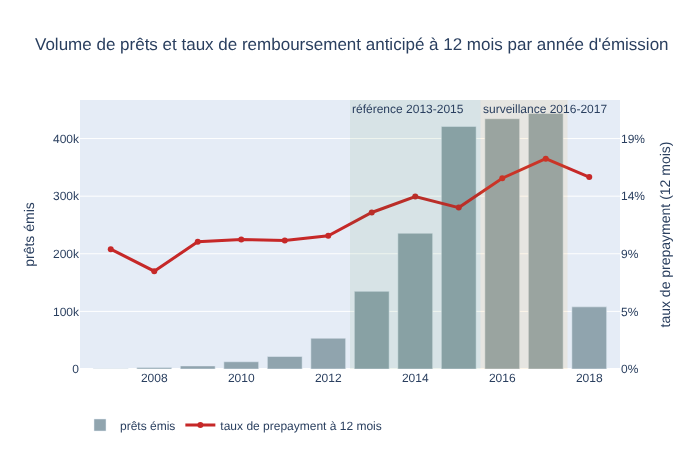

In [7]:
fig = go.Figure()
fig.add_trace(
    go.Bar(
        x=cohortes.index, y=cohortes["prets"], name="prêts émis", marker_color="#90a4ae", yaxis="y"
    )
)
fig.add_trace(
    go.Scatter(
        x=cohortes.index,
        y=cohortes["taux_prepayment"],
        name="taux de prepayment à 12 mois",
        mode="lines+markers",
        line={"color": "#c62828", "width": 3},
        yaxis="y2",
    )
)
fig.add_vrect(
    x0=2012.5,
    x1=2015.5,
    fillcolor="#2e7d32",
    opacity=0.08,
    line_width=0,
    annotation_text="référence 2013-2015",
    annotation_position="top left",
)
fig.add_vrect(
    x0=2015.5,
    x1=2017.5,
    fillcolor="#f9a825",
    opacity=0.10,
    line_width=0,
    annotation_text="surveillance 2016-2017",
    annotation_position="top left",
)
fig.update_layout(
    title="Volume de prêts et taux de remboursement anticipé à 12 mois par année d'émission",
    yaxis={"title": "prêts émis"},
    yaxis2={
        "title": "taux de prepayment (12 mois)",
        "overlaying": "y",
        "side": "right",
        "tickformat": ".0%",
        "range": [0, 0.22],
    },
    legend={"orientation": "h", "y": -0.15},
    height=450,
)
fig.show()

**Lecture.** Le volume explose à partir de 2013 (Lending Club devient une plateforme de masse). Le
taux de remboursement anticipé à 12 mois est stable autour de **10-11 %** jusqu'en 2012, monte à
**13-14 %** sur 2013-2015 (notre référence), puis continue de grimper : **15,6 % en 2016** et
**17,2 % en 2017**. La chute de 2018 est un artefact : seuls les prêts émis jusqu'en février 2018 sont
observables, et cette cohorte est différente (voir ci-dessous).

C'est précisément cette **hausse du niveau** que le modèle, entraîné sur 2013-2015, ne verra pas
venir : elle sera au cœur du monitoring du notebook 03.

## 4. Le biais de censure et la cible à horizon fixe

Pourquoi ne pas définir simplement la cible comme « le prêt a été remboursé avant son terme » ?
Parce que le fichier est une **photographie** prise en mars 2019 :

* un prêt de 60 mois émis en 2017 n'a pas encore atteint son terme : on ignore s'il sera remboursé
  en avance ou non ;
* parmi les prêts **déjà terminés** d'une cohorte récente, les seuls à avoir pu finir sont… ceux qui
  ont été remboursés très vite, ou ceux qui ont fait défaut. Les remboursements à l'échéance normale
  ne sont pas encore observés.

Mesurer « la part des prêts terminés qui sont prépayés » donne donc un taux **artificiellement
croissant** sur les cohortes récentes : c'est le **biais de censure**. On le met en évidence avec le
parquet brut (avant préparation), en comparant deux définitions sur chaque année d'émission.

In [8]:
brut = pd.read_parquet(
    f"{ROOT}/data/raw/lending_club_raw.parquet",
    columns=["issue_d", "loan_status", "last_pymnt_d", "term"],
)
emission = pd.to_datetime(brut["issue_d"].astype("string"), format="%b-%Y", errors="coerce")
dernier = pd.to_datetime(brut["last_pymnt_d"].astype("string"), format="%b-%Y", errors="coerce")
terme = brut["term"].astype("string").str.extract(r"(\d+)")[0].astype(float)
mois_actifs = (dernier.dt.year - emission.dt.year) * 12 + (dernier.dt.month - emission.dt.month)

statut = brut["loan_status"].astype("string")
solde = statut.isin(["Fully Paid", "Does not meet the credit policy. Status:Fully Paid"])
defaut = statut.str.contains("Charged Off", na=False)
termine = solde | defaut

obs = pd.DataFrame(
    {
        "annee": emission.dt.year,
        "termine": termine,
        "prepaye_naif": solde & (mois_actifs < terme - 1),  # soldé avant terme, sans horizon
        "prepaye_12m": solde & (mois_actifs <= 12) & (mois_actifs < terme - 1),
    }
)
censure = obs.groupby("annee").agg(prets=("termine", "size"), part_termines=("termine", "mean"))
censure["taux_naif_parmi_termines"] = obs[obs["termine"]].groupby("annee")["prepaye_naif"].mean()
censure["taux_horizon_12m"] = obs.groupby("annee")["prepaye_12m"].mean()
del brut, emission, dernier, terme, mois_actifs, statut, solde, defaut, termine
censure.round(3)

,prets,part_termines,taux_naif_parmi_termines,taux_horizon_12m
annee,,,,
2007,603,1.0,0.274,0.098
2008,2393,1.0,0.341,0.080
2009,5281,1.0,0.448,0.104
2010,12537,1.0,0.488,0.106
2011,21721,1.0,0.505,0.105
2012,53367,1.0,0.497,0.109
2013,134814,1.0,0.549,0.128
2014,235629,0.947,0.576,0.141
2015,421095,0.892,0.560,0.132


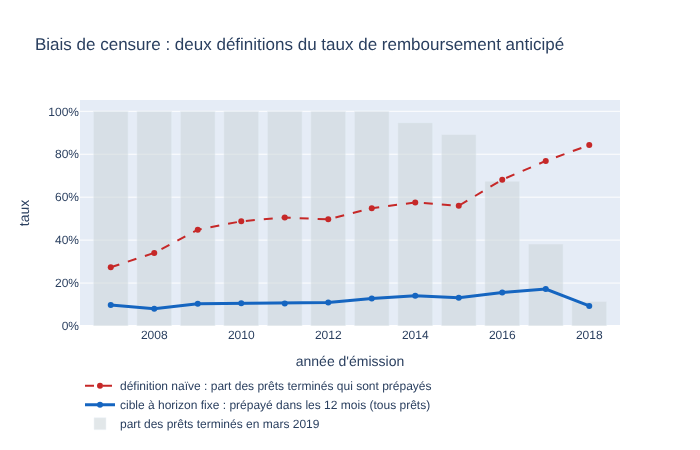

In [9]:
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=censure.index,
        y=censure["taux_naif_parmi_termines"],
        mode="lines+markers",
        name="définition naïve : part des prêts terminés qui sont prépayés",
        line={"color": "#c62828", "dash": "dash"},
    )
)
fig.add_trace(
    go.Scatter(
        x=censure.index,
        y=censure["taux_horizon_12m"],
        mode="lines+markers",
        name="cible à horizon fixe : prépayé dans les 12 mois (tous prêts)",
        line={"color": "#1565c0", "width": 3},
    )
)
fig.add_trace(
    go.Bar(
        x=censure.index,
        y=censure["part_termines"],
        name="part des prêts terminés en mars 2019",
        marker_color="#cfd8dc",
        opacity=0.6,
    )
)
fig.update_layout(
    title="Biais de censure : deux définitions du taux de remboursement anticipé",
    yaxis={"tickformat": ".0%", "title": "taux"},
    xaxis={"title": "année d'émission"},
    legend={"orientation": "h", "y": -0.2},
    height=450,
)
fig.show()

**Lecture.** Avec la définition naïve, le taux de prepayment atteint **84 % en 2018** : pas parce que
les emprunteurs de 2018 remboursent massivement en avance, mais parce que seuls 11 % des prêts de
2018 sont terminés, et que ceux-là sont quasi tous des remboursements précoces. La courbe rouge
raconte la censure, pas le comportement client.

La **cible à horizon fixe de 12 mois** (courbe bleue) est comparable d'une cohorte à l'autre :
chaque prêt a eu exactement le même temps pour prépayer. Le package va plus loin en **excluant les
cohortes dont l'horizon n'est pas écoulé** (d'où le jeu préparé qui s'arrête en février 2018 ; la
cohorte 2018 partielle n'est pas utilisée dans le monitoring). C'est le même raisonnement qu'un taux
de défaut à 12 mois en risque de crédit.

## 5. Ce qui bouge dans le temps

Un modèle entraîné sur 2013-2015 suppose implicitement que les prêts de 2016-2017 ressemblent à ceux
de la référence. On regarde trois variables clés par année d'émission. Les figures sont tracées sur un
**échantillon de 200 000 prêts** (les médianes, elles, sont calculées sur tout le jeu).

In [10]:
ech = df.sample(200_000, random_state=42)
medianes = df.groupby("annee")[["int_rate", "fico", "dti", "loan_amnt"]].median().round(2)
medianes.loc[2010:]

,int_rate,fico,dti,loan_amnt
annee,,,,
2010,11.86,712.0,13.240000,9300.0
2011,11.99,712.0,13.920000,10000.0
2012,13.67,697.0,16.480000,12000.0
2013,14.33,692.0,16.889999,13000.0
2014,13.65,687.0,17.629999,13000.0
2015,12.29,687.0,18.600000,14000.0
2016,11.99,692.0,18.219999,12400.0
2017,12.62,697.0,17.950001,12000.0
2018,11.98,702.0,17.629999,14000.0


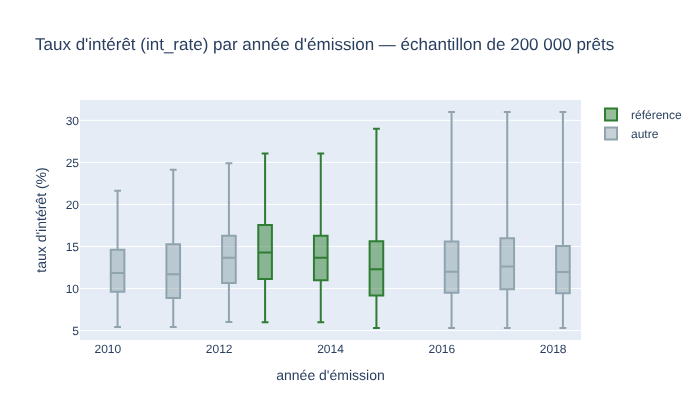

In [11]:
fig = px.box(
    ech[ech["annee"] >= 2010],
    x="annee",
    y="int_rate",
    color=ech.loc[ech["annee"] >= 2010, "annee"]
    .between(2013, 2015)
    .map({True: "référence", False: "autre"}),
    title="Taux d'intérêt (int_rate) par année d'émission — échantillon de 200 000 prêts",
    labels={"int_rate": "taux d'intérêt (%)", "annee": "année d'émission", "color": ""},
    color_discrete_map={"référence": "#2e7d32", "autre": "#90a4ae"},
    points=False,
)
fig.update_layout(height=420, showlegend=True)
fig.show()

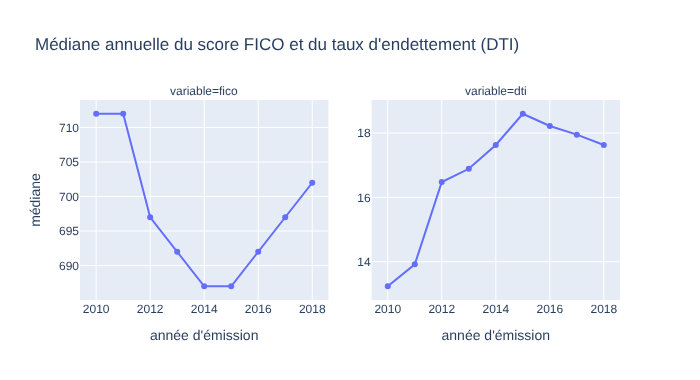

In [12]:
fig = px.line(
    medianes.loc[2010:].reset_index().melt(id_vars="annee", value_vars=["fico", "dti"]),
    x="annee",
    y="value",
    facet_col="variable",
    facet_col_spacing=0.08,
    markers=True,
    title="Médiane annuelle du score FICO et du taux d'endettement (DTI)",
    labels={"value": "médiane", "annee": "année d'émission"},
)
fig.update_yaxes(matches=None, showticklabels=True)
fig.update_layout(height=380)
fig.show()

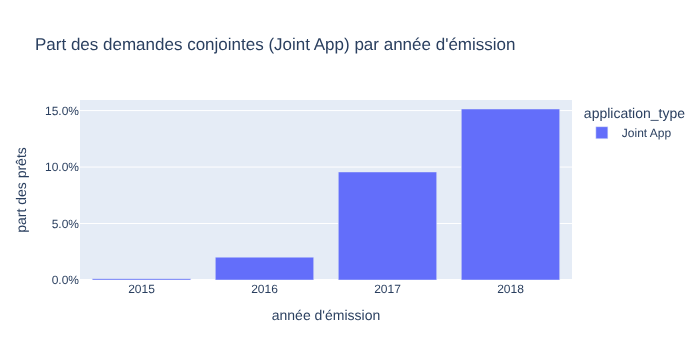

In [13]:
part = (
    df[df["annee"] >= 2012]
    .groupby("annee")["application_type"]
    .value_counts(normalize=True)
    .rename("part")
    .reset_index()
)
fig = px.bar(
    part[part["application_type"] != "Individual"],
    x="annee",
    y="part",
    color="application_type",
    title="Part des demandes conjointes (Joint App) par année d'émission",
    labels={"part": "part des prêts", "annee": "année d'émission"},
)
fig.update_yaxes(tickformat=".1%")
fig.update_layout(height=360)
fig.show()

**Lecture.**

* **int_rate** : la distribution des taux se déplace d'une année à l'autre, parce que Lending Club
  révise régulièrement sa **grille tarifaire** par grade. Après une baisse continue de 2013 à 2016, la médiane
  remonte en 2017 (12,0 % → 12,6 %). Pour un
  modèle de prepayment c'est doublement sensible : le taux est à la fois une feature importante et
  le moteur économique du refinancement.
* **FICO** : la médiane reste dans une bande étroite (687-712) : la qualité de crédit à l'octroi ne
  dérive pas vraiment.
* **DTI** : le taux d'endettement médian **augmente régulièrement** (de ~13 en 2010 à ~18-19 depuis
  2015) : la politique d'octroi s'assouplit, ce qui modifie le profil des emprunteurs.
* **application_type** : les **demandes conjointes** sont quasi inexistantes avant 2016 et
  représentent plusieurs pourcents des prêts en 2017 : une modalité presque « nouvelle » par rapport
  à la référence.

## 6. Valeurs manquantes

Les candidats du benchmark sont tous robustes aux valeurs manquantes (imputation ou gestion native),
mais le monitoring surveille le **taux de manquants par colonne** : une hausse brutale signale un
problème de flux amont avant même que la performance ne soit mesurable.

In [14]:
periode = (
    df["annee"]
    .between(2013, 2015)
    .map({True: "référence 2013-2015", False: "autres années"})
    .rename("periode")
)
manquants = (
    df.groupby(periode)[list(lc.NUMERIC_FEATURES)].apply(lambda d: d.isna().mean()).T.round(4)
)
manquants = manquants[["référence 2013-2015", "autres années"]]
manquants = manquants[manquants.max(axis=1) > 0].sort_values(
    "référence 2013-2015", ascending=False
)
manquants.index.name = "feature"
manquants.style.format("{:.2%}")

periode,référence 2013-2015,autres années
feature,,
emp_length_years,5.28%,6.71%
revol_util,0.48%,0.39%
dti,0.00%,0.20%
annual_inc,0.00%,0.08%
mort_acc,0.00%,4.62%
pub_rec_bankruptcies,0.00%,0.13%


Seules `emp_length_years` (~6 %) et `mort_acc` (~3 % sur la référence, car la variable n'était pas
collectée avant 2012) ont des manquants structurels ; `dti` et `revol_util` sont marginaux. Le seuil
d'alerte de la configuration de monitoring est donc fixé **au-dessus** de ces niveaux structurels
(warning à 10 %), pour ne réagir qu'à une hausse.

## 7. Conclusion

* La cible `prepaid_12m` est un **taux à horizon fixe**, seul moyen d'obtenir des cohortes comparables
  et d'éviter le biais de censure (84 % « de prepayment » en 2018 avec la définition naïve, contre un
  taux réel de l'ordre de 10 à 17 %).
* Les 23 colonnes post-octroi sont **bannies** du jeu préparé : la question de la fuite de données est
  traitée en amont, puis vérifiée par un audit (notebook 02).
* Entre la référence 2013-2015 et la période de surveillance 2016-2017, plusieurs choses bougent :
  le **niveau du taux de prepayment** (13 % → 17 %), la **grille de taux d'intérêt**, le **DTI** et
  l'apparition des **demandes conjointes**. Un modèle figé en 2016 est donc exposé à une dérive de
  données et surtout à une dérive de niveau : c'est ce que les KPIs du notebook 03 doivent détecter.